# CIFAR-10 Image Classification using EfficientNetB0
Fast Google Colab version. For quick testing, this notebook uses a subset of CIFAR-10. Select **Runtime → Change runtime type → T4 GPU** before running.

## 1. Data Preparation

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

(X_train_all, y_train_all), (X_test_all, y_test_all) = tf.keras.datasets.cifar10.load_data()
y_train_all, y_test_all = y_train_all.flatten(), y_test_all.flatten()

# Small subsets for faster execution
X_train, y_train = X_train_all[:5000], y_train_all[:5000]
X_val, y_val = X_train_all[45000:46000], y_train_all[45000:46000]
X_test, y_test = X_test_all[:2000], y_test_all[:2000]

class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

TensorFlow: 2.21.0
GPU: []
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1279s 7us/step
Train: (5000, 32, 32, 3) Validation: (1000, 32, 32, 3) Test: (2000, 32, 32, 3)


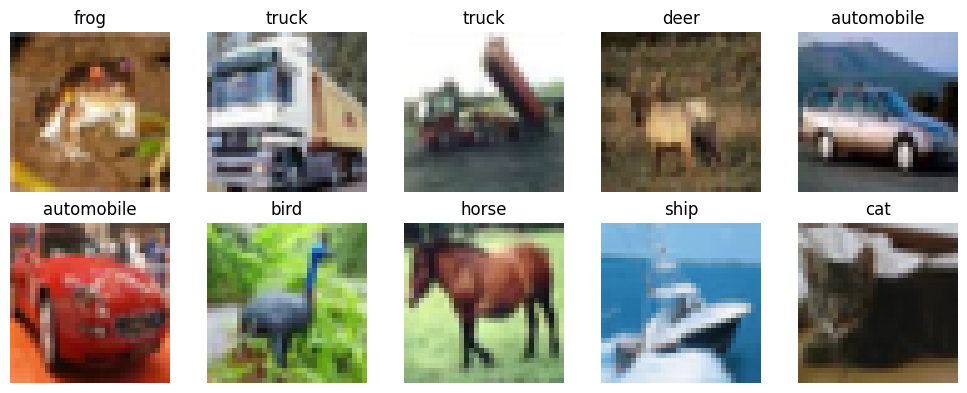

In [2]:
IMG_SIZE = 96
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

def prepare_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return tf.cast(image, tf.float32), tf.cast(label, tf.int32)

def make_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(5000, seed=42)
    return ds.map(prepare_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

# Display sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 2. Model Implementation

In [3]:
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.RandomFlip("horizontal")(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

model = Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 3, 3, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 3. Model Training

In [4]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/2
79/79 ━━━━━━━━━━━━━━━━━━━━ 48s 519ms/step - accuracy: 0.5952 - loss: 1.3236 - val_accuracy: 0.7810 - val_loss: 0.7778
Epoch 2/2
79/79 ━━━━━━━━━━━━━━━━━━━━ 40s 503ms/step - accuracy: 0.7852 - loss: 0.7192 - val_accuracy: 0.8050 - val_loss: 0.6259


## 4. Performance Evaluation

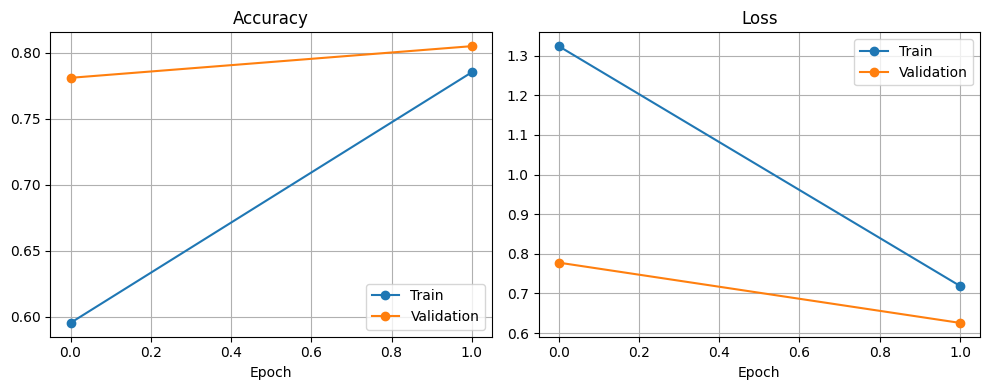

32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 450ms/step
Accuracy : 0.812
Precision: 0.8116
Recall   : 0.8111
F1-score : 0.8097


In [5]:
# Training curves
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Train")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Train")
plt.plot(history.history["val_loss"], marker="o", label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Test metrics
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))

## 5. Result Analysis

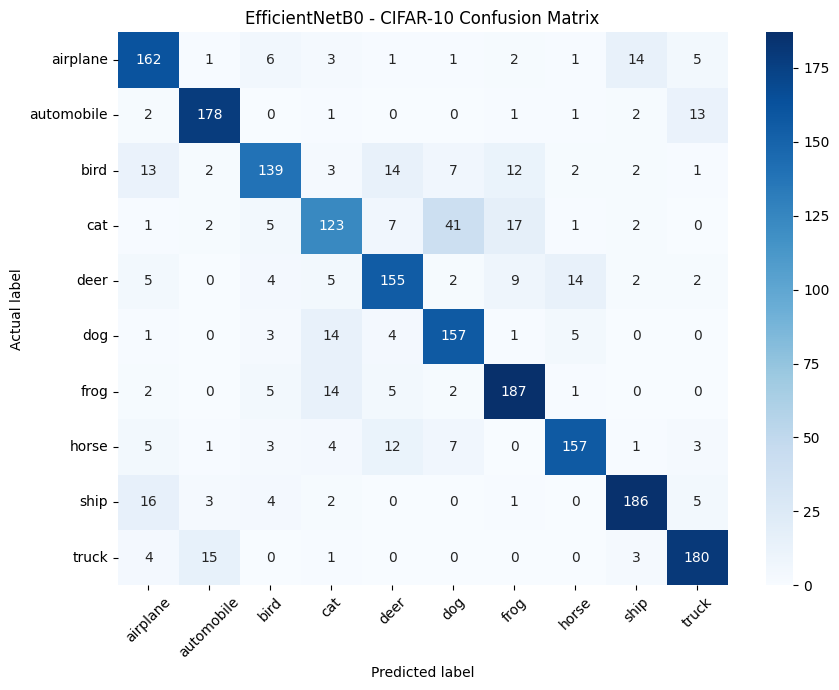

              precision    recall  f1-score   support

    airplane       0.77      0.83      0.80       196
  automobile       0.88      0.90      0.89       198
        bird       0.82      0.71      0.76       195
         cat       0.72      0.62      0.67       199
        deer       0.78      0.78      0.78       198
         dog       0.72      0.85      0.78       185
        frog       0.81      0.87      0.84       216
       horse       0.86      0.81      0.84       193
        ship       0.88      0.86      0.87       217
       truck       0.86      0.89      0.87       203

    accuracy                           0.81      2000
   macro avg       0.81      0.81      0.81      2000
weighted avg       0.81      0.81      0.81      2000



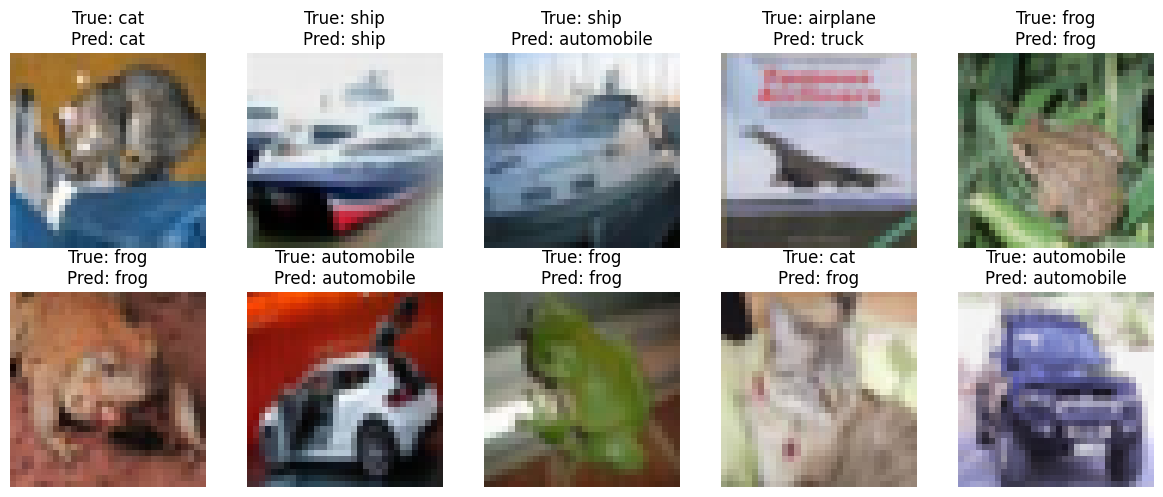

Correct predictions: 1624 / 2000
Incorrect predictions: 376 / 2000

Note: This is a fast subset experiment, not a full-dataset benchmark.


In [6]:
# Confusion matrix and class-wise report
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("EfficientNetB0 - CIFAR-10 Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(classification_report(
    y_test, y_pred, labels=np.arange(10),
    target_names=class_names, zero_division=0
))

# Example predictions
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])
    plt.title(f"True: {class_names[y_test[i]]}\nPred: {class_names[y_pred[i]]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

print("Correct predictions:", int(np.sum(y_test == y_pred)), "/", len(y_test))
print("Incorrect predictions:", int(np.sum(y_test != y_pred)), "/", len(y_test))
print("\nNote: This is a fast subset experiment, not a full-dataset benchmark.")